In [1]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

In [2]:
# Step 1: Import data

train = pd.read_csv('../data/processed/race_driver_records_train_fe.csv')
test = pd.read_csv('../data/processed/race_driver_records_test_fe.csv')

exclude_cols = [
    'is_podium',
    'raceId', 'driverId', 'constructorId', 'circuitId',
    'driver_name', 'forename', 'surname', 'driverRef',
    'name',
    'name_constructor', 'constructorRef',
    'circuitRef', 'name_circuit', 'location', 'country',
    'weather_raw',
    'date', 'dob',
    'position',
    'points',
    'milliseconds', 'time',
    'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed',
    'laps',
    'nationality',
    'nationality_constructor',
    'weather_category',
    'positionText', 'position',
    'resultId',
    'number',
    'positionOrder',
    'statusId',
    'grid',
]

X_train = train.drop(columns=exclude_cols)
X_train = X_train.fillna(X_train.median())
y_train = train['is_podium']


In [29]:
# Step 2: Binary Logistic Regression

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/opt/anaconda3/lib/python3.13/site-packages/skl

LogisticRegression(max_iter=1000, random_state=42)

In [30]:
# Step 3: Check for multicollinarity with VIF

vif_data = pd.DataFrame()
vif_data['Feature'] = X_train_scaled.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_train_scaled.values, i) 
    for i in range(X_train_scaled.shape[1])
]

vif_data = vif_data.sort_values('VIF', ascending=False)
print(vif_data)

                      Feature        VIF
8     prev_constructor_points  13.617603
11          driver_avg_pos_y1  13.231415
6          prev_driver_points  13.076908
23     constructor_avg_pos_y2  13.046827
31      driver_avg_pos_dry_3y  12.557580
26     constructor_avg_pos_y3  12.421372
17          driver_avg_pos_y3  11.793240
14          driver_avg_pos_y2  10.551325
19  constructor_podium_pct_y1  10.319570
20     constructor_avg_pos_y1  10.300581
22  constructor_podium_pct_y2  10.165286
25  constructor_podium_pct_y3   8.168146
10       driver_podium_pct_y1   8.087349
13       driver_podium_pct_y2   6.537671
16       driver_podium_pct_y3   6.138843
18            driver_races_y3   5.679500
27       constructor_races_y3   4.932522
32      driver_avg_pos_wet_3y   4.857307
15            driver_races_y2   4.396451
24       constructor_races_y2   4.223807
12            driver_races_y1   3.017093
5               grid_position   2.267081
21       constructor_races_y1   2.166584
7        prev_dr

In [5]:
# Step 4: What's statistically significant 

X_train_with_const = sm.add_constant(X_train_scaled)

logit_model = sm.Logit(y_train, X_train_with_const)
result = logit_model.fit()

print(result.summary())

Optimization terminated successfully.
         Current function value: 0.211370
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:              is_podium   No. Observations:                 5857
Model:                          Logit   Df Residuals:                     5823
Method:                           MLE   Df Model:                           33
Date:                Fri, 03 Jul 2026   Pseudo R-squ.:                  0.4812
Time:                        12:56:19   Log-Likelihood:                -1238.0
converged:                       True   LL-Null:                       -2386.4
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                        -4.0522      0.149    -27.253      0.000      -4.

In [6]:
p_values = result.pvalues

significant_features = p_values[p_values < 0.05].index.tolist()
significant_features.remove('const')  

print(significant_features)

X_train_reduced = X_train_scaled[significant_features]
print(f"\nReduced from {X_train_scaled.shape[1]} to {X_train_reduced.shape[1]} features")

['year', 'round', 'grid_position', 'prev_driver_points', 'prev_constructor_points', 'driver_podium_pct_y2', 'driver_avg_pos_y2', 'driver_podium_pct_y3', 'constructor_races_y1', 'constructor_podium_pct_y2', 'constructor_podium_pct_y3', 'driver_avg_pos_dry_3y', 'driver_avg_pos_wet_3y']

Reduced from 33 to 13 features


In [7]:
model_reduced = LogisticRegression(
    solver='liblinear',
    max_iter=5000,
    random_state=42
)
model_reduced.fit(X_train_reduced, y_train)

LogisticRegression(max_iter=5000, random_state=42, solver='liblinear')

In [8]:
# Check VIF on reduced feature set

vif_reduced = pd.DataFrame()
vif_reduced['Feature'] = X_train_reduced.columns
vif_reduced['VIF'] = [
    variance_inflation_factor(X_train_reduced.values, i) 
    for i in range(X_train_reduced.shape[1])
]

vif_reduced = vif_reduced.sort_values('VIF', ascending=False)
print("VIF for Reduced Feature Set:")
print("="*50)
print(vif_reduced)
print("\n")
print(f"Features with VIF > 10: {len(vif_reduced[vif_reduced['VIF'] > 10])}")
print(f"Features with VIF > 5: {len(vif_reduced[vif_reduced['VIF'] > 5])}")
print("\nInterpretation:")
print("  VIF < 5: Low multicollinearity")
print("  VIF 5-10: Moderate multicollinearity")
print("  VIF > 10: High multicollinearity")

VIF for Reduced Feature Set:
                      Feature        VIF
4     prev_constructor_points  11.377814
3          prev_driver_points  11.287948
11      driver_avg_pos_dry_3y   6.848411
6           driver_avg_pos_y2   6.136407
5        driver_podium_pct_y2   4.698873
9   constructor_podium_pct_y2   4.523393
12      driver_avg_pos_wet_3y   4.043737
10  constructor_podium_pct_y3   3.760334
7        driver_podium_pct_y3   2.920312
2               grid_position   1.923532
1                       round   1.208373
8        constructor_races_y1   1.122744
0                        year   1.058597


Features with VIF > 10: 2
Features with VIF > 5: 4

Interpretation:
  VIF < 5: Low multicollinearity
  VIF 5-10: Moderate multicollinearity
  VIF > 10: High multicollinearity


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


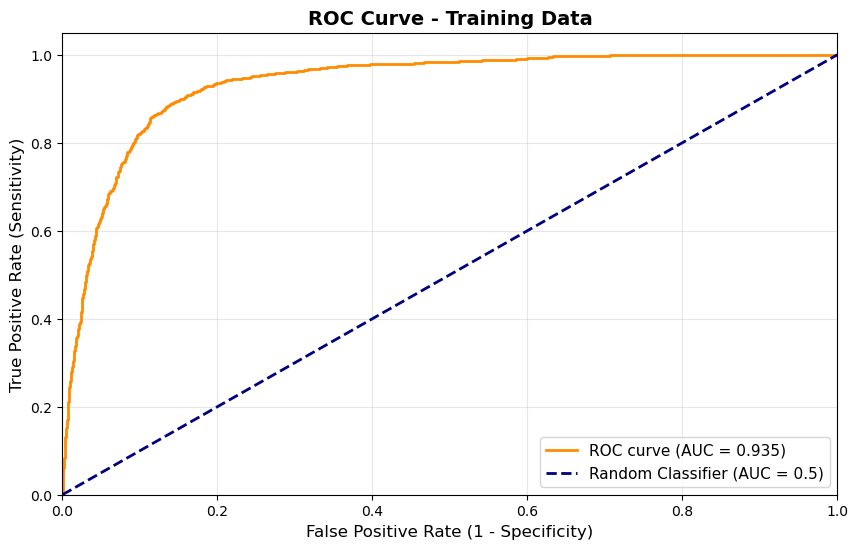

AUC Score: 0.9345

Interpretation:
  AUC = 0.5: No discriminative power (random guessing)
  AUC = 0.7-0.8: Acceptable discrimination
  AUC = 0.8-0.9: Excellent discrimination
  AUC > 0.9: Outstanding discrimination


In [9]:
# Step 5: ROC Curve and AUC for Train Data

from sklearn.metrics import roc_curve, roc_auc_score, auc
import matplotlib.pyplot as plt

y_train_pred_proba = model_reduced.predict_proba(X_train_reduced)[:, 1]

fpr_train, tpr_train, thresholds_train = roc_curve(y_train, y_train_pred_proba)
roc_auc_train = roc_auc_score(y_train, y_train_pred_proba)

plt.figure(figsize=(10, 6))
plt.plot(fpr_train, tpr_train, color='darkorange', lw=2, 
         label=f'ROC curve (AUC = {roc_auc_train:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier (AUC = 0.5)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('ROC Curve - Training Data', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.show()

print("="*60)
print(f"AUC Score: {roc_auc_train:.4f}")
print("\nInterpretation:")
print("  AUC = 0.5: No discriminative power (random guessing)")
print("  AUC = 0.7-0.8: Acceptable discrimination")
print("  AUC = 0.8-0.9: Excellent discrimination")
print("  AUC > 0.9: Outstanding discrimination")

In [10]:
# Step 6: Classification Table and Accuracy (using default threshold 0.5)

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

y_train_pred = model_reduced.predict(X_train_reduced)

cm_train = confusion_matrix(y_train, y_train_pred)

print("="*60)
print("STEP 6: CLASSIFICATION TABLE AND ACCURACY - TRAIN DATA")
print("="*60)
print("\nConfusion Matrix (Threshold = 0.5):")
print("-" * 40)
print(f"                 Predicted")
print(f"                 No Podium  |  Podium")
print(f"Actual  No Podium    {cm_train[0,0]:5d}   |   {cm_train[0,1]:5d}")
print(f"        Podium       {cm_train[1,0]:5d}   |   {cm_train[1,1]:5d}")
print("-" * 40)

accuracy = accuracy_score(y_train, y_train_pred)
tn, fp, fn, tp = cm_train.ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
f1 = 2 * (precision * sensitivity) / (precision + sensitivity) if (precision + sensitivity) > 0 else 0

print(f"\nPerformance Metrics:")
print(f"  Accuracy:    {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"  Sensitivity: {sensitivity:.4f} (Recall - % of actual podiums correctly predicted)")
print(f"  Specificity: {specificity:.4f} (% of actual non-podiums correctly predicted)")
print(f"  Precision:   {precision:.4f} (% of predicted podiums that were correct)")
print(f"  F1-Score:    {f1:.4f}")

print("\nDetailed Classification Report:")
print(classification_report(y_train, y_train_pred, target_names=['No Podium', 'Podium']))

STEP 6: CLASSIFICATION TABLE AND ACCURACY - TRAIN DATA

Confusion Matrix (Threshold = 0.5):
----------------------------------------
                 Predicted
                 No Podium  |  Podium
Actual  No Podium     4816   |     213
        Podium         343   |     485
----------------------------------------

Performance Metrics:
  Accuracy:    0.9051 (90.51%)
  Sensitivity: 0.5857 (Recall - % of actual podiums correctly predicted)
  Specificity: 0.9576 (% of actual non-podiums correctly predicted)
  Precision:   0.6948 (% of predicted podiums that were correct)
  F1-Score:    0.6356

Detailed Classification Report:
              precision    recall  f1-score   support

   No Podium       0.93      0.96      0.95      5029
      Podium       0.69      0.59      0.64       828

    accuracy                           0.91      5857
   macro avg       0.81      0.77      0.79      5857
weighted avg       0.90      0.91      0.90      5857



/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [13]:
# Step 7: Find the optimal threshold to balance Specificity vs Sensitivity
# Using Youden's J

j_scores = tpr_train - fpr_train
optimal_idc = np.argmax(j_scores)
optimal_threshold = thresholds_train[optimal_idc]

print("="*60)
print("Step 7: Optimal Threshold")
print("="*60)
print(f"\n Threshold from Youden's J: {optimal_threshold:.3f}")


Step 7: Optimal Threshold

 Threshold from Youden's J: 0.187


In [17]:
y_train_pred_optimal = (y_train_pred_proba >= optimal_threshold).astype(int)
cm_optimal = confusion_matrix(y_train, y_train_pred_optimal)
tn, fp, fn, tp = cm_optimal.ravel()

sensitivity_opt = tp / (tp + fn)
specificity_opt = tn / (tn + fp)
accuracy_opt = (tp + tn) / (tp + tn + fp + fn)

print(f"\nPerformance at optimal threshold:")
print(f"  Sensitivity: {sensitivity_opt:.4f}")
print(f"  Specificity: {specificity_opt:.4f}")
print(f"  Accuracy:    {accuracy_opt:.4f}")

print(f"\nComparison to default threshold (0.5):")
print(f"  Threshold 0.5   -> Sensitivity: 0.5857, Specificity: 0.9576")
print(f"  Threshold {optimal_threshold:.3f} -> Sensitivity: {sensitivity_opt:.4f}, Specificity: {specificity_opt:.4f}")


Performance at optimal threshold:
  Sensitivity: 0.8889
  Specificity: 0.8614
  Accuracy:    0.8653

Comparison to default threshold (0.5):
  Threshold 0.5   -> Sensitivity: 0.5857, Specificity: 0.9576
  Threshold 0.187 -> Sensitivity: 0.8889, Specificity: 0.8614


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


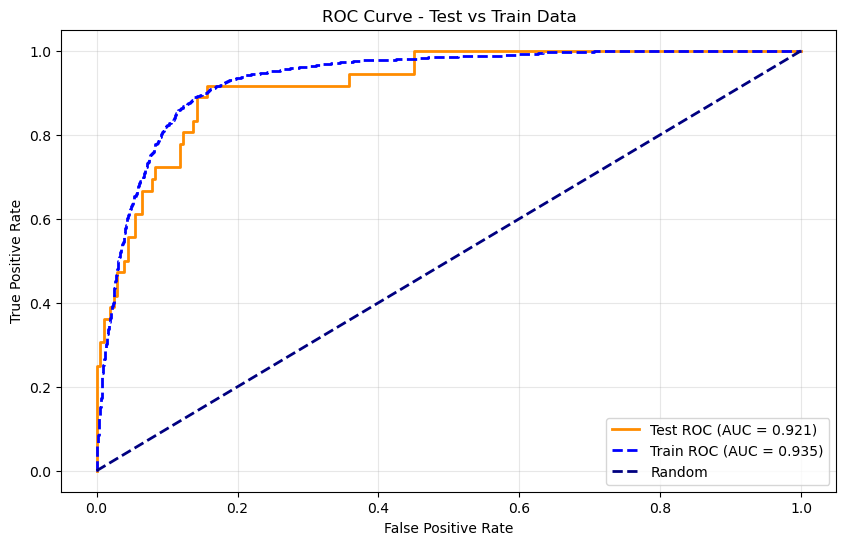

STEP 8: TEST DATA ROC AND AUC

Train AUC: 0.9345
Test AUC:  0.9208
Difference: 0.0137

Interpretation:
Difference < 0.05: Excellent generalization
Difference 0.05-0.10: Good generalization
Difference > 0.10: Possible overfitting


In [23]:
# Step 8: ROC Curve and AUC for Test Data

X_test = test.drop(columns=exclude_cols)
X_test = X_test.fillna(X_test.median())
y_test = test['is_podium']

X_test_scaled = scaler.transform(X_test)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)
X_test_reduced = X_test_scaled[significant_features]

y_test_pred_proba = model_reduced.predict_proba(X_test_reduced)[:, 1]

fpr_test, tpr_test, thresholds_test = roc_curve(y_test, y_test_pred_proba)
roc_auc_test = roc_auc_score(y_test, y_test_pred_proba)

plt.figure(figsize=(10, 6))
plt.plot(fpr_test, tpr_test, color='darkorange', lw=2,
         label=f'Test ROC (AUC = {roc_auc_test:.3f})')
plt.plot(fpr_train, tpr_train, color='blue', lw=2, linestyle='--',
         label=f'Train ROC (AUC = {roc_auc_train:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test vs Train Data')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print("="*60)
print("STEP 8: TEST DATA ROC AND AUC")
print("="*60)
print(f"\nTrain AUC: {roc_auc_train:.4f}")
print(f"Test AUC:  {roc_auc_test:.4f}")
print(f"Difference: {abs(roc_auc_train - roc_auc_test):.4f}")
print("\nInterpretation:")
print("Difference < 0.05: Excellent generalization")
print("Difference 0.05-0.10: Good generalization")
print("Difference > 0.10: Possible overfitting")



In [31]:
# Step 9: Test Data Performance at Optimal Threshold

y_test_pred_optimal = (y_test_pred_proba >= optimal_threshold).astype(int)
cm_test = confusion_matrix(y_test, y_test_pred_optimal)

tn, fp, fn, tp = cm_test.ravel()
sensitivity_test = tp / (tp + fn)
specificity_test = tn / (tn + fp)
accuracy_test = (tp + tn) / (tp + tn + fp + fn)


print("="*60)
print("STEP 9: TEST DATA PERFORMANCE AT OPTIMAL THRESHOLD")
print("="*60)
print(f"\nUsing threshold = {optimal_threshold:.3f} (from training data)")
print(f"\nConfusion Matrix:")
print(f"                 No Podium  |  Podium")
print(f"  No Podium        {tn:5d}   |   {fp:5d}")
print(f"  Podium           {fn:5d}   |   {tp:5d}")
print(f"\nTest Data Metrics:")
print(f"Sensitivity: {sensitivity_test:.4f}")
print(f"Specificity: {specificity_test:.4f}")
print(f"Accuracy:    {accuracy_test:.4f}")
print(f"\nComparison (Train vs Test at threshold {optimal_threshold:.3f}):")
print(f"Train: Sens={sensitivity_opt:.4f}, Spec={specificity_opt:.4f}, Acc={accuracy_opt:.4f}")
print(f"Test:  Sens={sensitivity_test:.4f}, Spec={specificity_test:.4f}, Acc={accuracy_test:.4f}")

STEP 9: TEST DATA PERFORMANCE AT OPTIMAL THRESHOLD

Using threshold = 0.187 (from training data)

Confusion Matrix:
                 No Podium  |  Podium
  No Podium          176   |      28
  Podium               6   |      30

Test Data Metrics:
Sensitivity: 0.8333
Specificity: 0.8627
Accuracy:    0.8583

Comparison (Train vs Test at threshold 0.187):
Train: Sens=0.8889, Spec=0.8614, Acc=0.8653
Test:  Sens=0.8333, Spec=0.8627, Acc=0.8583


In [33]:
# Step 10-11: Compare Different Feature Versions

def evaluate_model(feature_list, model_name):
    """Run full workflow on a feature set and return test AUC"""

    # Train model
    X_train_subset = X_train_scaled[feature_list]
    model = LogisticRegression(solver='liblinear', max_iter=5000, random_state=42)
    model.fit(X_train_subset, y_train)

    # Test predictions
    X_test_subset = X_test_scaled[feature_list]
    y_test_pred_proba = model.predict_proba(X_test_subset)[:, 1]

    # Calculate test AUC
    test_auc = roc_auc_score(y_test, y_test_pred_proba)

    # Find optimal threshold on train
    y_train_pred_proba = model.predict_proba(X_train_subset)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_train, y_train_pred_proba)
    j_scores = tpr - fpr
    optimal_idx = np.argmax(j_scores)
    optimal_thresh = thresholds[optimal_idx]

    # Test performance at optimal threshold
    y_test_pred = (y_test_pred_proba >= optimal_thresh).astype(int)
    cm = confusion_matrix(y_test, y_test_pred)
    tn, fp, fn, tp = cm.ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    return {
        'model_name': model_name,
        'n_features': len(feature_list),
        'test_auc': test_auc,
        'optimal_threshold': optimal_thresh,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'accuracy': accuracy,
        'features': feature_list
    }

# Version 1: Current model (p < 0.05) - already done
version1_features = significant_features

# Version 2: Stricter p-value (p < 0.01)
version2_features = p_values[p_values < 0.01].index.tolist()
if 'const' in version2_features:
    version2_features.remove('const')

# Version 3: Remove high VIF features (VIF > 10)
high_vif_features = ['prev_constructor_points', 'prev_driver_points']
version3_features = [f for f in significant_features if f not in high_vif_features]

# Version 4: Domain knowledge - most interpretable features
version4_features = [
    'grid_position',
    'driver_avg_pos_y2',
    'constructor_podium_pct_y2',
    'driver_avg_pos_dry_3y',
    'driver_avg_pos_wet_3y'
]

# Evaluate all versions
results = []
results.append(evaluate_model(version1_features, "Version 1: p < 0.05 (Current)"))
results.append(evaluate_model(version2_features, "Version 2: p < 0.01 (Stricter)"))
results.append(evaluate_model(version3_features, "Version 3: Remove High VIF"))
results.append(evaluate_model(version4_features, "Version 4: Domain Knowledge"))

# Compare results
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('test_auc', ascending=False)

print("="*60)
print("STEP 11: MODEL COMPARISON (sorted by Test AUC)")
print("="*60)
print(results_df[['model_name', 'n_features', 'test_auc', 'sensitivity', 'specificity', 'accuracy']])

print(f"\n{'='*60}")
print(f"FINAL MODEL: {results_df.iloc[0]['model_name']}")
print(f"Test AUC: {results_df.iloc[0]['test_auc']:.4f}")
print(f"Features ({results_df.iloc[0]['n_features']}): {results_df.iloc[0]['features']}")
print(f"{'='*60}")

STEP 11: MODEL COMPARISON (sorted by Test AUC)
                       model_name  n_features  test_auc  sensitivity  \
2      Version 3: Remove High VIF          11  0.923339     0.805556   
0   Version 1: p < 0.05 (Current)          13  0.920752     0.833333   
1  Version 2: p < 0.01 (Stricter)           9  0.920752     0.861111   
3     Version 4: Domain Knowledge           5  0.919322     0.861111   

   specificity  accuracy  
2     0.857843  0.850000  
0     0.862745  0.858333  
1     0.867647  0.866667  
3     0.838235  0.841667  

FINAL MODEL: Version 3: Remove High VIF
Test AUC: 0.9233
Features (11): ['year', 'round', 'grid_position', 'driver_podium_pct_y2', 'driver_avg_pos_y2', 'driver_podium_pct_y3', 'constructor_races_y1', 'constructor_podium_pct_y2', 'constructor_podium_pct_y3', 'driver_avg_pos_dry_3y', 'driver_avg_pos_wet_3y']


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/anaconda3/lib/python3.